# Анализ трёх пар «чертёж — CAD-модель»

## Кратко

Исходный корпус содержит 27 пар; здесь рассматриваем только **шестерню KF0011,
прорезную втулку KF0017 и кольцо KF0027**.

Проверяем, какую геометрию задаёт каждый лист, какие обозначения требуют внимания
и согласуется ли чертёж с приложенной моделью. Числа берём из файлов, содержание
чертежей разбираем вручную. На этом этапе изучаем исходные данные и определяем ограничения для будущих запусков.

In [1]:
import hashlib
import json
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import trimesh
from IPython.display import Image as NotebookImage
from IPython.display import display
from matplotlib.colors import LightSource
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from PIL import Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/manifest.json").exists())
DATA = ROOT / "data"


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


inventory = read_json(DATA / "manifest.json")
items = {item["pair_id"]: item for item in inventory["items"]}
names = {"KF0011": "Шестерня", "KF0017": "Прорезная втулка", "KF0027": "Кольцо"}
roles = {"dev": "Отладка", "val": "Проверка"}
assert set(items) == set(names), "Изменился состав рассматриваемых пар"
for relative, expected in inventory["files"].items():
    actual = hashlib.sha256((DATA / relative).read_bytes()).hexdigest()
    assert actual == expected, f"Файл изменён: {relative}"

plt.rcParams.update({"font.size": 11, "figure.dpi": 150})
print("Исходные файлы трёх пар совпадают с описью по контрольным суммам.")

Исходные файлы трёх пар совпадают с описью по контрольным суммам.


## 1. Что входит в выборку

У каждой пары есть изображение чертежа PNG, исходный чертёж CDW и эталонная модель M3D.
Шестерня — отладочный пример; втулка и кольцо — кандидаты для проверки метода.

In [2]:
rows = []
for key, item in items.items():
    path = DATA / item["input_png"]["path"]
    with Image.open(path) as picture:
        width, height = picture.size
        assert (width, height) == (item["input_png"]["width_px"], item["input_png"]["height_px"])
        assert picture.mode == "RGB", "Изменился цветовой формат изображения"
    rows.append(
        {
            "Пара": key,
            "Деталь": names[key],
            "Назначение": roles[item["split"]],
            "Размер изображения, пикс.": f"{width} × {height}",
            "Размер PNG, КиБ": round(path.stat().st_size / 1024, 1),
        }
    )
display(pd.DataFrame(rows).set_index("Пара"))

,Деталь,Назначение,"Размер изображения, пикс.","Размер PNG, КиБ"
Пара,,,,
KF0011,Шестерня,Отладка,4962 × 3509,372.3
KF0017,Прорезная втулка,Проверка,2481 × 3509,178.4
KF0027,Кольцо,Проверка,4962 × 3509,269.3


Изображения цветные: контуры синие, осевые линии оранжевые; на листе кольца размерные
надписи также выделены цветом. Цвет помогает различать элементы листа, поэтому для
просмотра сохраняем исходное изображение.

Ниже каждый лист показан отдельно. В вывод ячейки помещён **исходный PNG без уменьшения
числа пикселей**; ширина на экране ограничена для удобства. Важные фрагменты дополнительно
показаны в исходном размере. Ссылки под заголовками открывают полные изображения.

## 2. KF0011 — шестерня

[Открыть исходный чертёж](../data/input/KF0011.png)

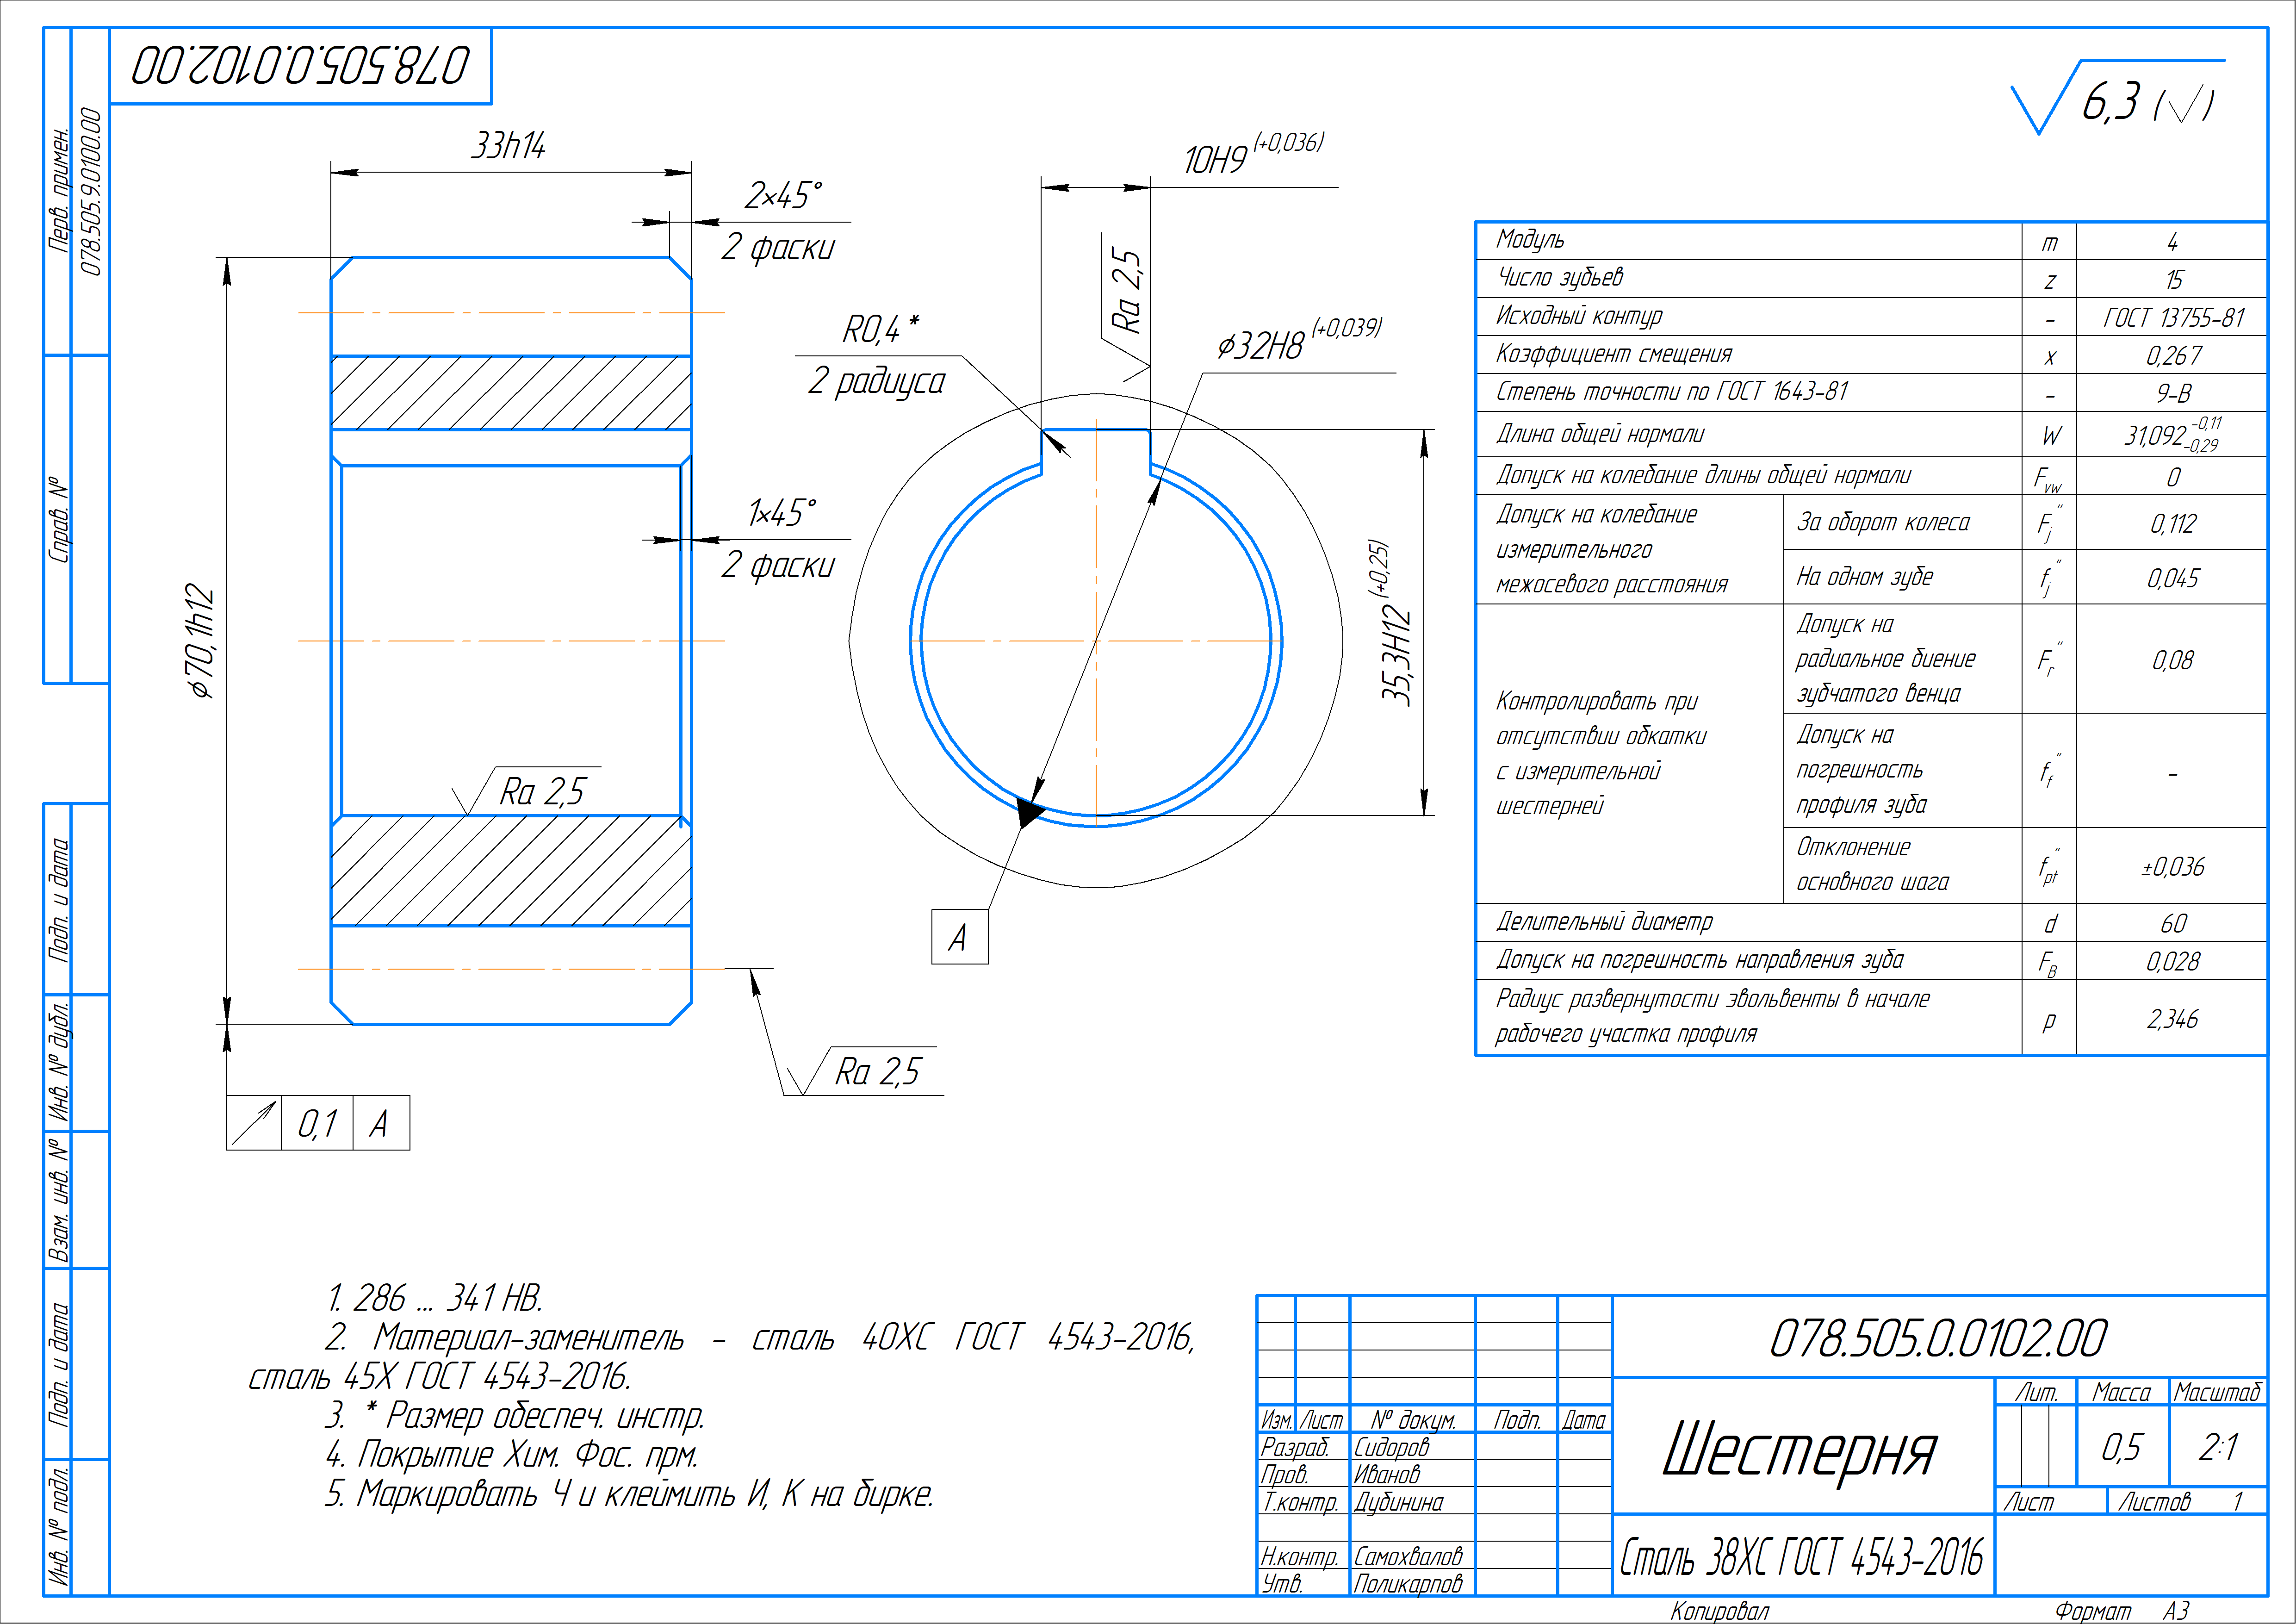

In [3]:
display(
    NotebookImage(
        filename=str(DATA / items["KF0011"]["input_png"]["path"]), width=1400, alt="Чертёж шестерни KF0011"
    )
)

**Фрагмент: основные параметры зубчатого венца.** Верхняя часть таблицы содержит сведения, которых нет
в упрощённом контуре на видах. Координаты фрагмента заданы в пикселях исходного листа.

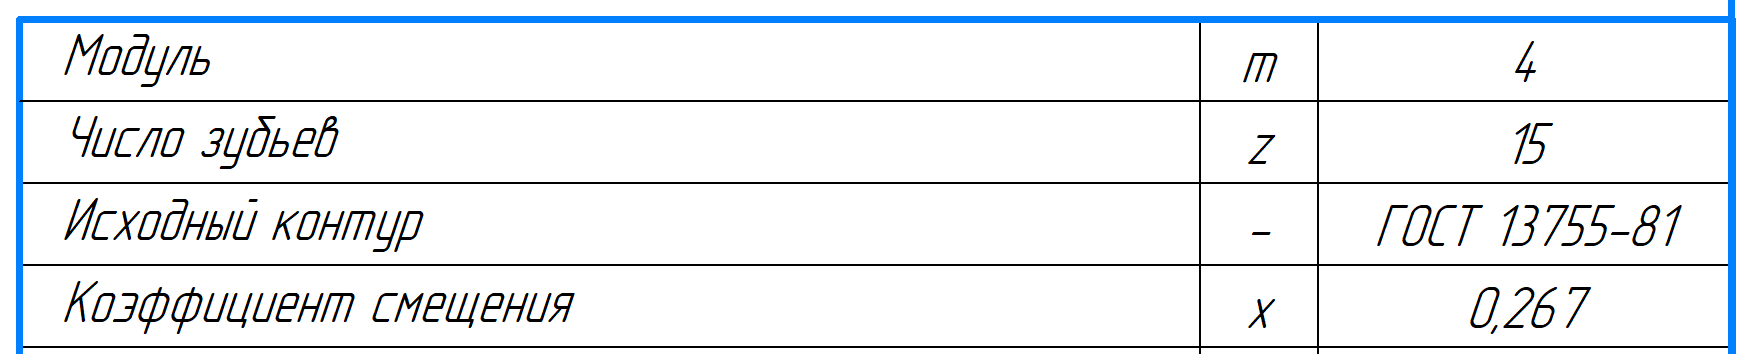

In [4]:
def show_fragment(pair_id: str, box: tuple[int, int, int, int]) -> None:
    with Image.open(DATA / items[pair_id]["input_png"]["path"]) as picture:
        fragment = picture.crop(box)
        buffer = BytesIO()
        fragment.save(buffer, format="PNG")
    display(
        NotebookImage(
            data=buffer.getvalue(), unconfined=True, alt=f"Фрагмент чертежа {pair_id} в исходном размере"
        )
    )


show_fragment("KF0011", (3170, 460, 4920, 814))

**Что читается на листе.** Слева дан продольный разрез, в центре — торцевой вид,
справа — таблица зубчатого венца. Указаны ширина 33 мм, наружный диаметр 70,1 мм,
отверстие Ø32H8 и шпоночный паз шириной 10H9. В таблице: модуль 4, число зубьев 15,
коэффициент смещения 0,267 и делительный диаметр 60 мм.

**На что обратить внимание.** Зубья не прорисованы поштучно на торцевом виде.
Для восстановления венца нужно совместно читать виды и таблицу. Фаски и радиусы
показаны отдельными выносками; обозначения шероховатости не задают новые вырезы.
Сопоставление с моделью ниже выявляет расхождение диаметра отверстия.

## 3. KF0017 — прорезная втулка

[Открыть исходный чертёж](../data/input/KF0017.png)

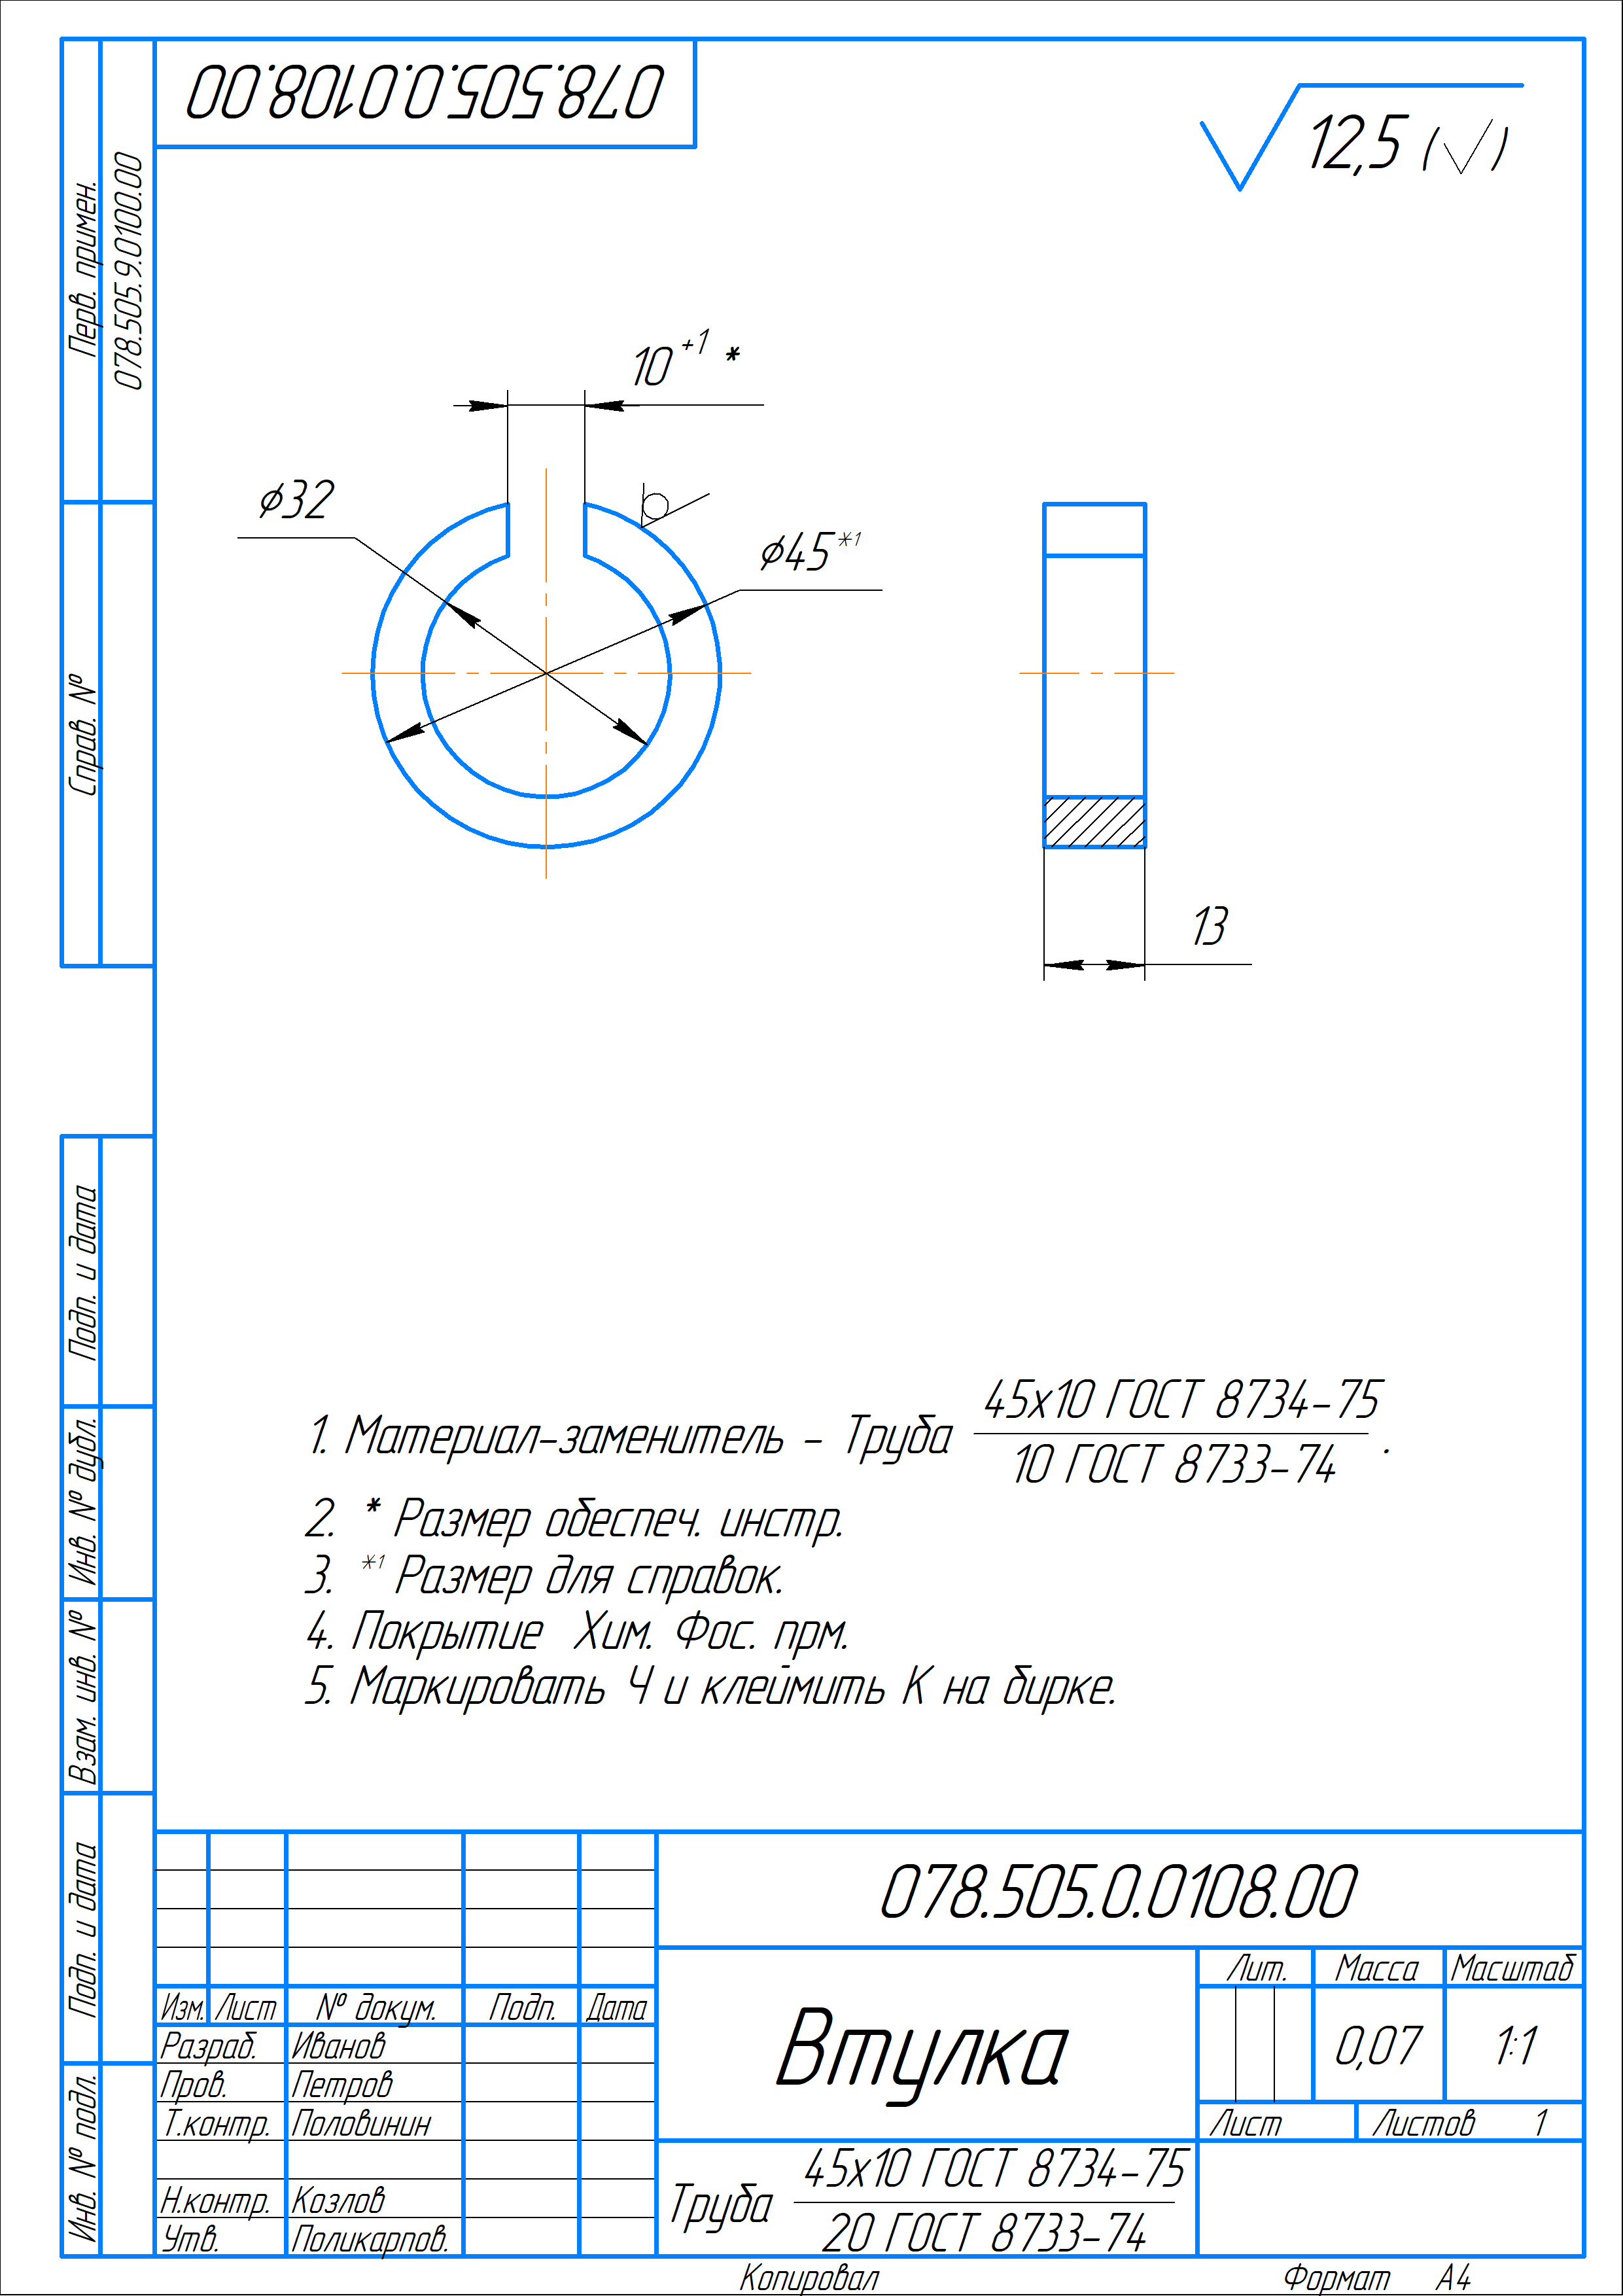

In [5]:
display(
    NotebookImage(
        filename=str(DATA / items["KF0017"]["input_png"]["path"]),
        width=1100,
        alt="Чертёж прорезной втулки KF0017",
    )
)

**Фрагмент: диаметры и прорезь.** Здесь важно прочитать и числовые значения, и знаки
возле них: допуск ширины прорези и ссылку на справочный размер.

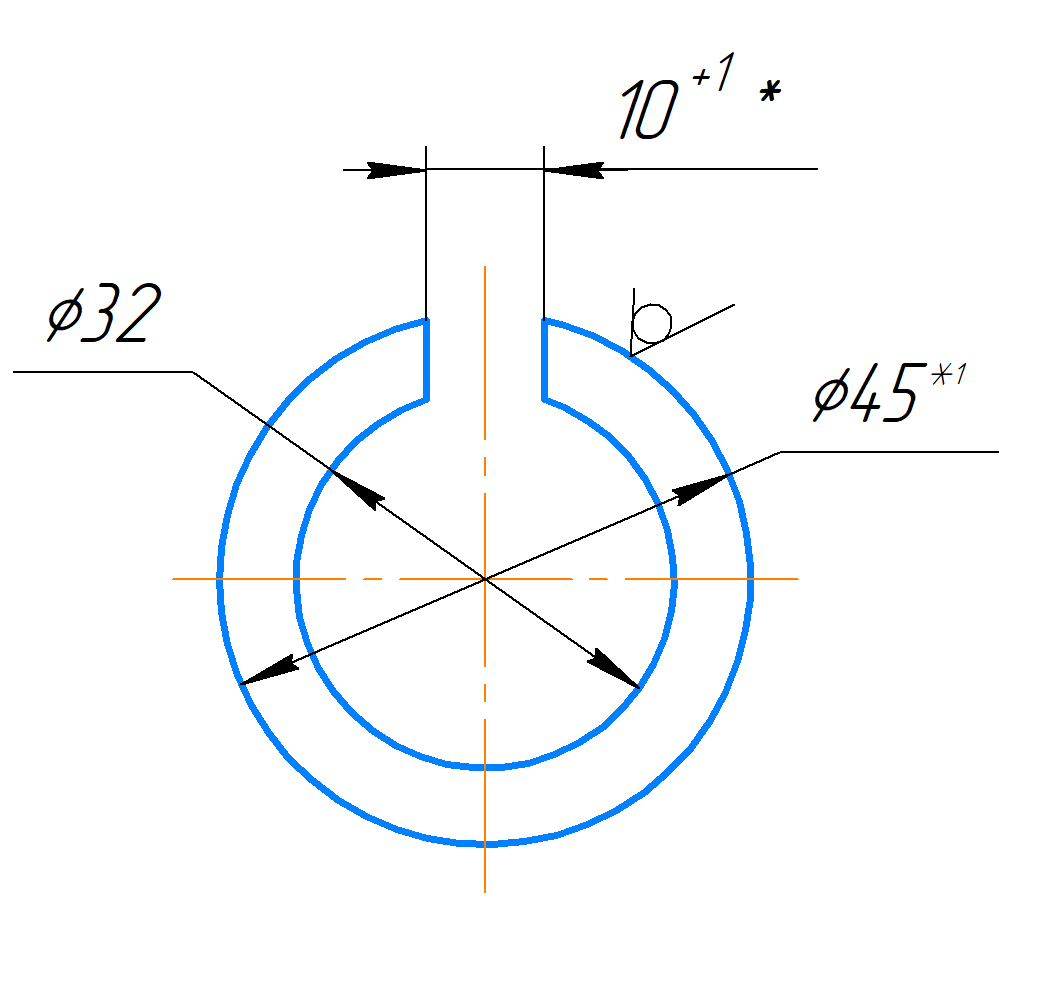

In [6]:
show_fragment("KF0017", (350, 450, 1400, 1450))

**Что читается на листе.** Торцевой вид задаёт наружный диаметр 45 мм, отверстие 32 мм
и прорезь номинальной шириной 10 мм с верхним отклонением +1 мм. Боковой вид задаёт
толщину 13 мм. Наружный диаметр помечен как справочный.

**На что обратить внимание.** Штриховка в нижней части бокового вида показывает
местный разрез стенки. Дополнительная выемка в этом месте не задана. Для номинальной
модели используем ширину прорези 10 мм; допуск +1 мм описывает допустимое отклонение,
а не обязательное увеличение прорези до 11 мм.

## 4. KF0027 — кольцо с отверстиями

[Открыть исходный чертёж](../data/input/KF0027.png)

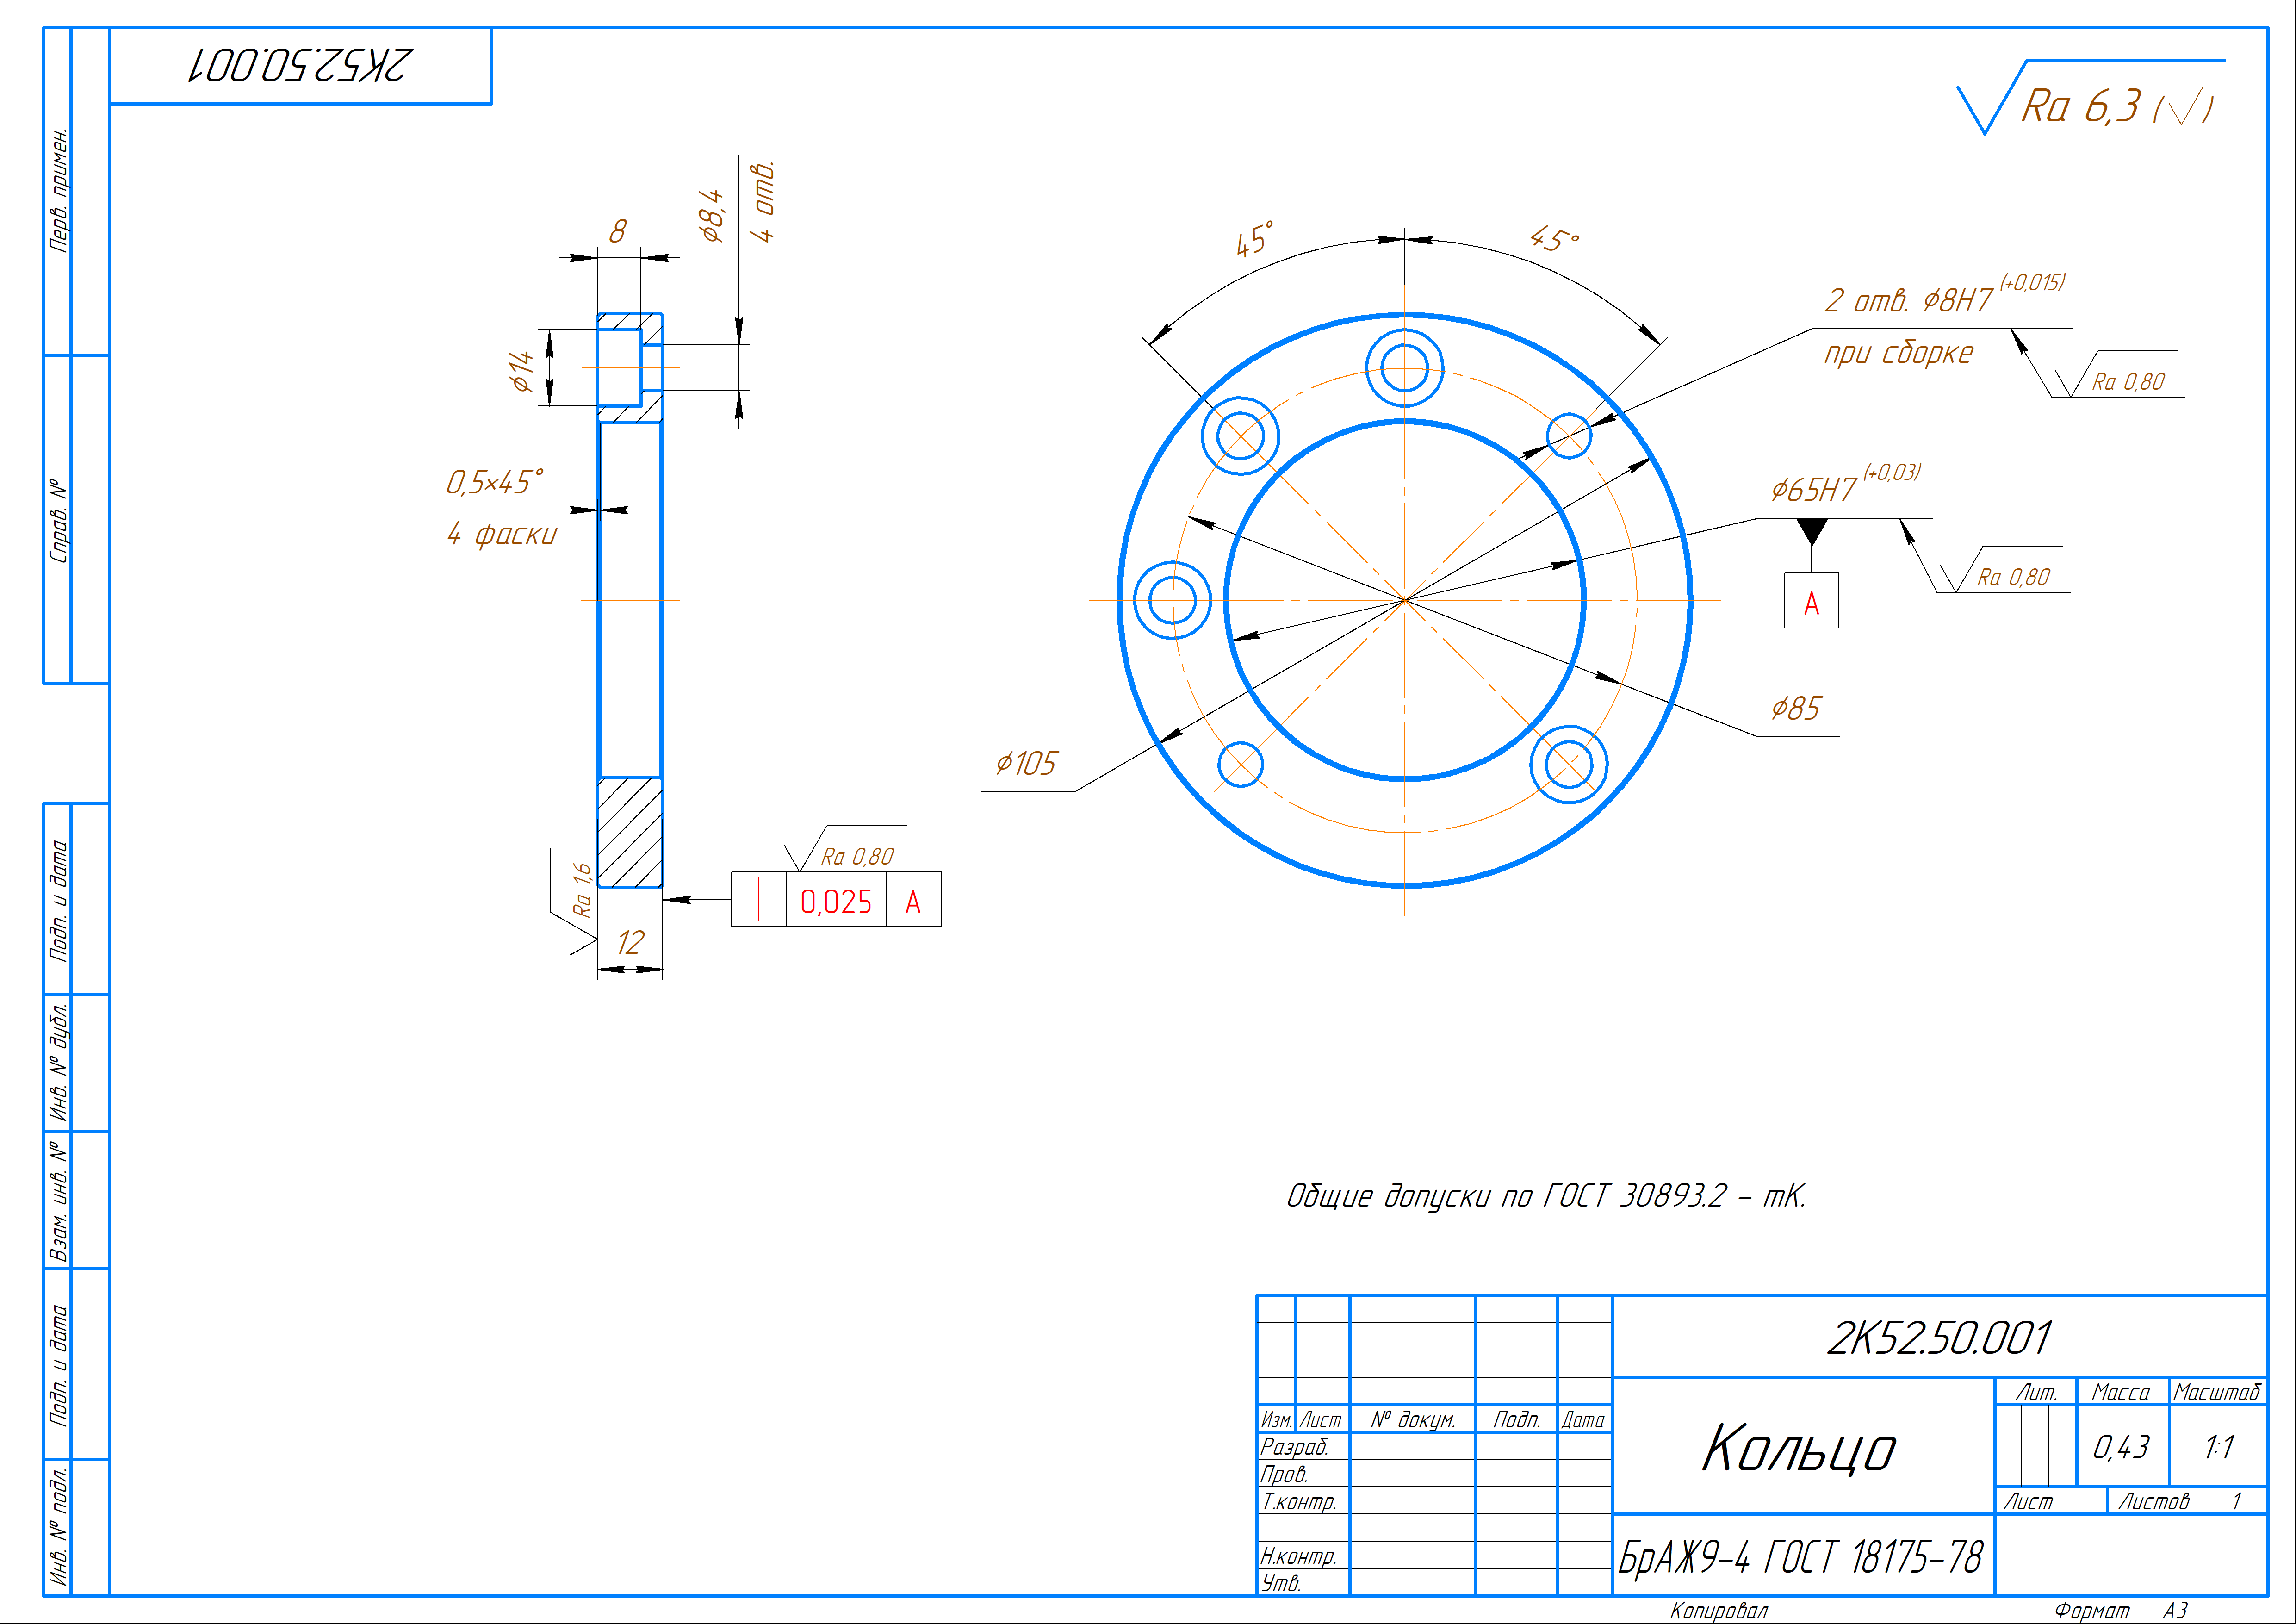

In [7]:
display(
    NotebookImage(
        filename=str(DATA / items["KF0027"]["input_png"]["path"]), width=1400, alt="Чертёж кольца KF0027"
    )
)

**Фрагмент: ступенчатое отверстие в разрезе.** Цековка — цилиндрическое расширение
отверстия под головку крепежа. На разрезе читаются её диаметр и глубина.

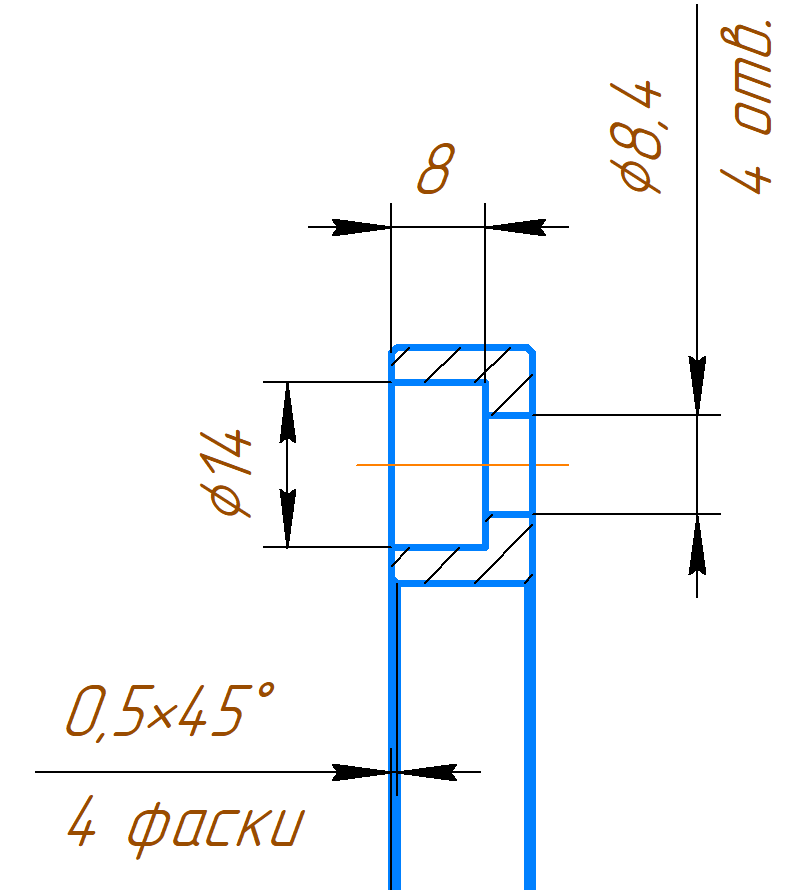

In [8]:
show_fragment("KF0027", (900, 330, 1710, 1220))

**Что читается на листе.** Наружный диаметр кольца 105 мм, центральное отверстие 65 мм,
толщина 12 мм; центры малых отверстий лежат на окружности Ø85. Показаны две группы:
четыре отверстия Ø8,4 с цековками Ø14 глубиной 8 мм и два отверстия Ø8H7 с надписью
«при сборке». Для торцевых кромок указаны четыре фаски 0,5 × 45°.

**На что обратить внимание.** Отверстия двух групп имеют разные размеры и назначение;
их нельзя заменить шестью одинаковыми отверстиями с равным угловым шагом. Торцевой вид
нужен для расположения, разрез — для глубины цековок. В выбранной эталонной модели
отверстия «при сборке» уже присутствуют, поэтому для этой пары они входят в целевую форму.

## 5. Что содержат соответствующие модели

Для каждой пары в `data/reference/<ID>` собраны M3D, исходный CDW и выгрузки.
Читаем выгрузки **эталонных моделей**: треугольные сетки для изображения
и измерения КОМПАС для таблицы. Проверяем, что выгрузка относится к нужной M3D и сетка
не изменилась. Повторное подключение к КОМПАС не требуется.

Корректность тела означает корректность геометрического тела по сохранённому измерению.
Она сама по себе не подтверждает совпадение с чертежом.

In [9]:
exports = {key: DATA / item["reference_export"]["path"] for key, item in items.items()}
facts, meshes, model_rows = {}, {}, []
for key, directory in exports.items():
    facts[key] = read_json(directory / "eval-facts.json")
    assert facts[key]["native_sha256"] == items[key]["reference_m3d"]["sha256"], "Другая модель"
    mesh_path = directory / "model.stl"
    assert hashlib.sha256(mesh_path.read_bytes()).hexdigest() == facts[key]["mesh_sha256"], "Сетка изменена"
    assert facts[key]["units"] == "mm" and facts[key]["mesh_units"] == "mm"
    meshes[key] = trimesh.load_mesh(mesh_path, process=False)
    model_rows.append(
        {
            "Пара": key,
            "Корректное тело": "Да" if facts[key]["solid_valid"] else "Нет",
            "Число тел": facts[key]["body_count"],
            "Объём, мм³": round(facts[key]["volume_mm3"], 1),
            "Грани в модели": facts[key]["topology"]["faces"],
        }
    )
display(pd.DataFrame(model_rows).set_index("Пара"))

,Корректное тело,Число тел,"Объём, мм³",Грани в модели
Пара,,,,
KF0011,Да,1,71369.7,130
KF0017,Да,1,9365.3,6
KF0027,Да,1,56935.9,22


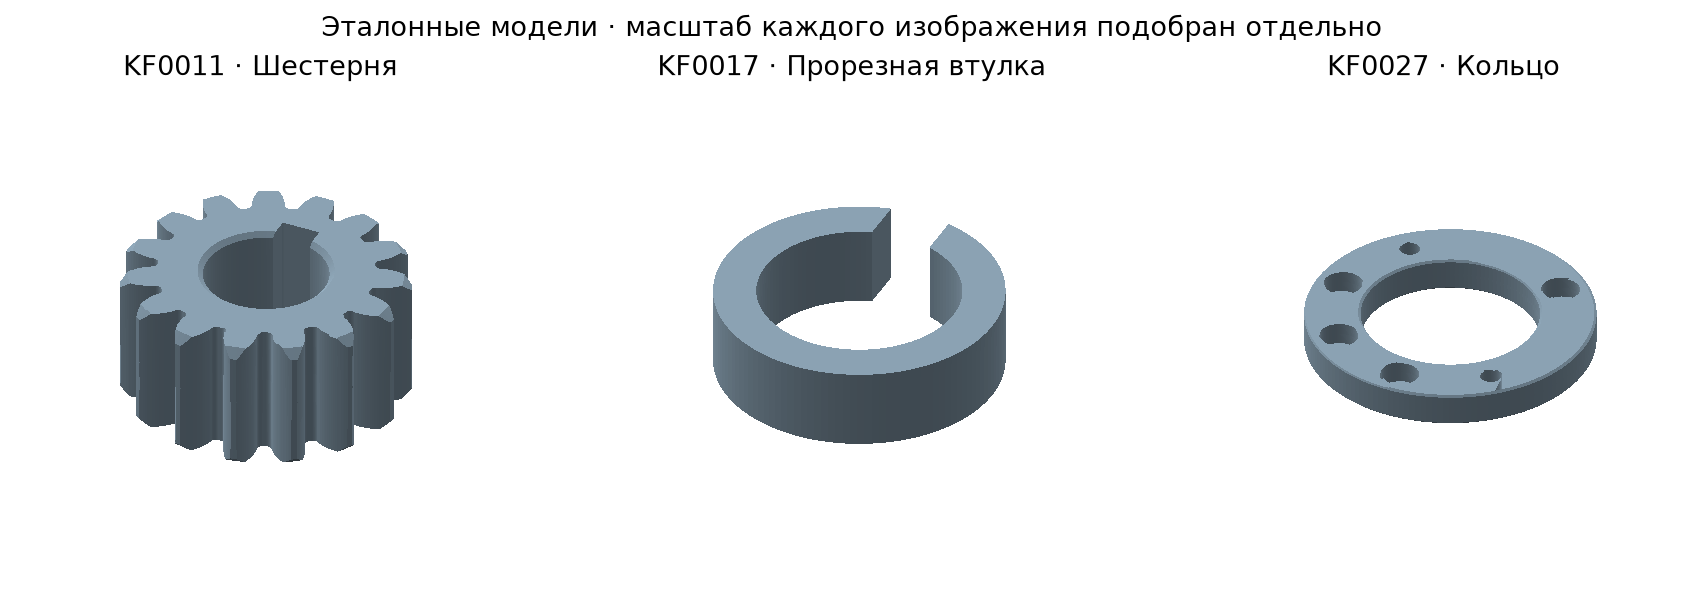

In [10]:
fig = plt.figure(figsize=(12, 4))
for index, (key, mesh) in enumerate(meshes.items(), start=1):
    axis = fig.add_subplot(1, 3, index, projection="3d")
    # Поворачиваем изображение так, чтобы тонкая ось детали была вертикальной.
    thin_axis = int(np.argmin(mesh.extents))
    order = [(thin_axis + 1) % 3, (thin_axis + 2) % 3, thin_axis]
    points = mesh.vertices[:, order]
    if key == "KF0027":
        points[:, [0, 2]] *= -1  # Показываем сторону с цековками.
    triangles = points[mesh.faces]
    # Скрываем обратные стороны треугольников для ортографического вида.
    elevation, azimuth = np.deg2rad([35, -65])
    direction = [np.cos(elevation) * np.cos(azimuth), np.cos(elevation) * np.sin(azimuth), np.sin(elevation)]
    normals = np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0])
    facing_camera = normals @ direction > 0
    faces = Poly3DCollection(
        triangles[facing_camera],
        facecolors="#9bb5c8",
        linewidths=0,
        antialiased=False,
        shade=True,
        lightsource=LightSource(315, 45),
    )
    axis.add_collection3d(faces)
    center = (points.min(axis=0) + points.max(axis=0)) / 2
    radius = np.ptp(points, axis=0).max() / 2
    axis.set(
        xlim=(center[0] - radius, center[0] + radius),
        ylim=(center[1] - radius, center[1] + radius),
        zlim=(center[2] - radius, center[2] + radius),
        title=f"{key} · {names[key]}",
    )
    axis.set_box_aspect((1, 1, 1))
    axis.set_proj_type("ortho")
    axis.view_init(elev=35, azim=-65)
    axis.set_axis_off()
fig.suptitle("Эталонные модели · масштаб каждого изображения подобран отдельно")
fig.tight_layout()
plt.show()

### Сопоставление отверстий

Значения с чертежей прочитаны вручную по выноскам на листах. Значения для моделей
взяты из сохранённых измерений соответствующих цилиндрических поверхностей.
Ячейка дополнительно проверяет наличие этих диаметров в выгрузке.

In [11]:
drawing_bores = {"KF0011": 32.0, "KF0017": 32.0, "KF0027": 65.0}
model_bores = {"KF0011": 30.6, "KF0017": 32.0, "KF0027": 65.0}
comparison = []
for key in names:
    dimensions = facts[key]["dimensions_mm"]
    diameters = dimensions["diameter"] + [2 * radius for radius in dimensions["radius"]]
    assert any(np.isclose(value, model_bores[key]) for value in diameters), "Диаметр не найден в выгрузке"
    comparison.append(
        {
            "Пара": key,
            "На чертеже, мм": drawing_bores[key],
            "В модели, мм": model_bores[key],
            "Разница, мм": round(abs(drawing_bores[key] - model_bores[key]), 1),
        }
    )
display(pd.DataFrame(comparison).set_index("Пара"))

,"На чертеже, мм","В модели, мм","Разница, мм"
Пара,,,
KF0011,32.0,30.6,1.4
KF0017,32.0,32.0,0.0
KF0027,65.0,65.0,0.0


У шестерни отверстие в модели меньше указанного на листе на **1,4 мм**. Это расхождение
исходной пары; его нельзя считать ошибкой генератора. Поэтому шестерню следует использовать
только для отладки и исключить из проверки качества будущего генератора.

Для втулки и кольца размеры отверстий согласуются. Предварительная проверка пары
включает размеры тела, прорезь втулки и отверстия с цековками кольца:
[проверка втулки](../data/reference/KF0017/review.json),
[проверка кольца](../data/reference/KF0027/review.json).
Это проверка номинальной геометрии; материал, шероховатость и производственные допуски
требуют отдельного контроля.

In [12]:
for field in ("input_png", "reference_m3d", "source_cdw"):
    hashes = [item[field]["sha256"] for item in items.values()]
    assert len(hashes) == len(set(hashes)), "Найден точный повтор файла"
family_roles = {}
for item in items.values():
    family_roles.setdefault(item["family"], set()).add(item["split"])
assert all(len(value) == 1 for value in family_roles.values()), "Семейство попало в обе части"
print("Точных повторов файлов PNG, CDW и M3D среди трёх пар нет.")
print("По разметке в описи одно семейство деталей не попадает одновременно в отладку и проверку.")

Точных повторов файлов PNG, CDW и M3D среди трёх пар нет.
По разметке в описи одно семейство деталей не попадает одновременно в отладку и проверку.


## 6. Выводы

- Исходные PNG позволяют прочитать размеры при просмотре в достаточном масштабе.
  В мелком масштабе особенно трудно прочитать таблицу параметров шестерни.
- Для каждой пары есть своя трудность интерпретации: параметры зубчатого венца,
  местный разрез втулки, разные группы отверстий кольца. Одного внешнего контура недостаточно.
- Все три эталона содержат корректное тело по сохранённым измерениям, но у шестерни
  найдено расхождение отверстия с чертежом. Корректность модели и корректность пары — разные проверки.
- По этим трём примерам нельзя оценить частоту ошибок во всём корпусе или качество метода
  на других деталях. Отсутствие точных повторов также не исключает знакомства модели
  с учебными примерами при предварительном обучении.